In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")
df=pd.read_csv(os.path.join(path, "AB_NYC_2019.csv"))
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'new-york-city-airbnb-open-data' dataset.
Path to dataset files: /kaggle/input/new-york-city-airbnb-open-data


In [5]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [7]:
df.shape


(48895, 16)

In [8]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [11]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


<Axes: xlabel='count', ylabel='room_type'>

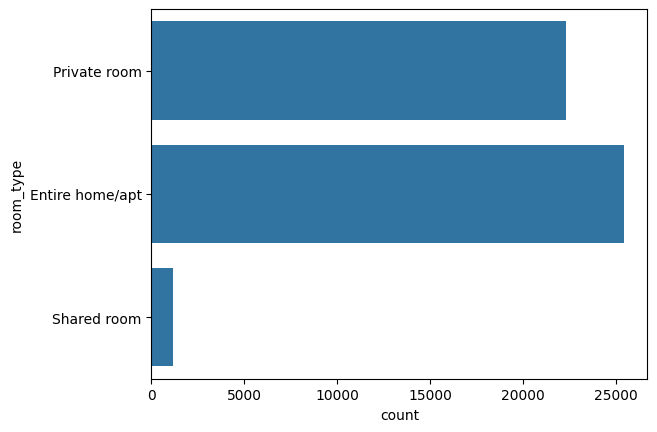

In [12]:

sns.countplot(df['room_type'])

In [13]:
df['room_type'].value_counts()

,count
room_type,
Entire home/apt,25409
Private room,22326
Shared room,1160


<Axes: xlabel='room_type', ylabel='count'>

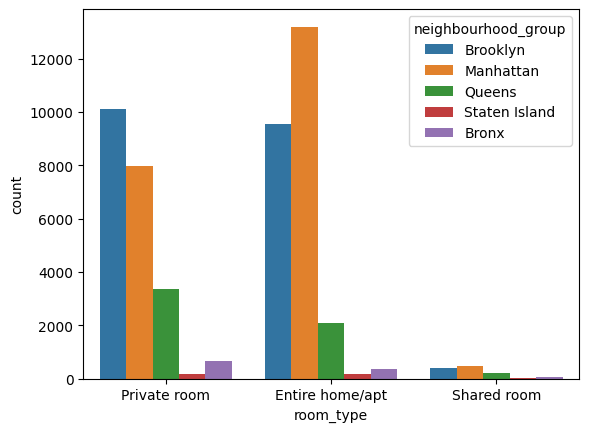

In [15]:

sns.countplot(x='room_type',data=df,hue='neighbourhood_group')

In [26]:
numeric_cols=['price','minimum_nights','number_of_reviews','reviews_per_month','calculated_host_listings_count','availability_365']

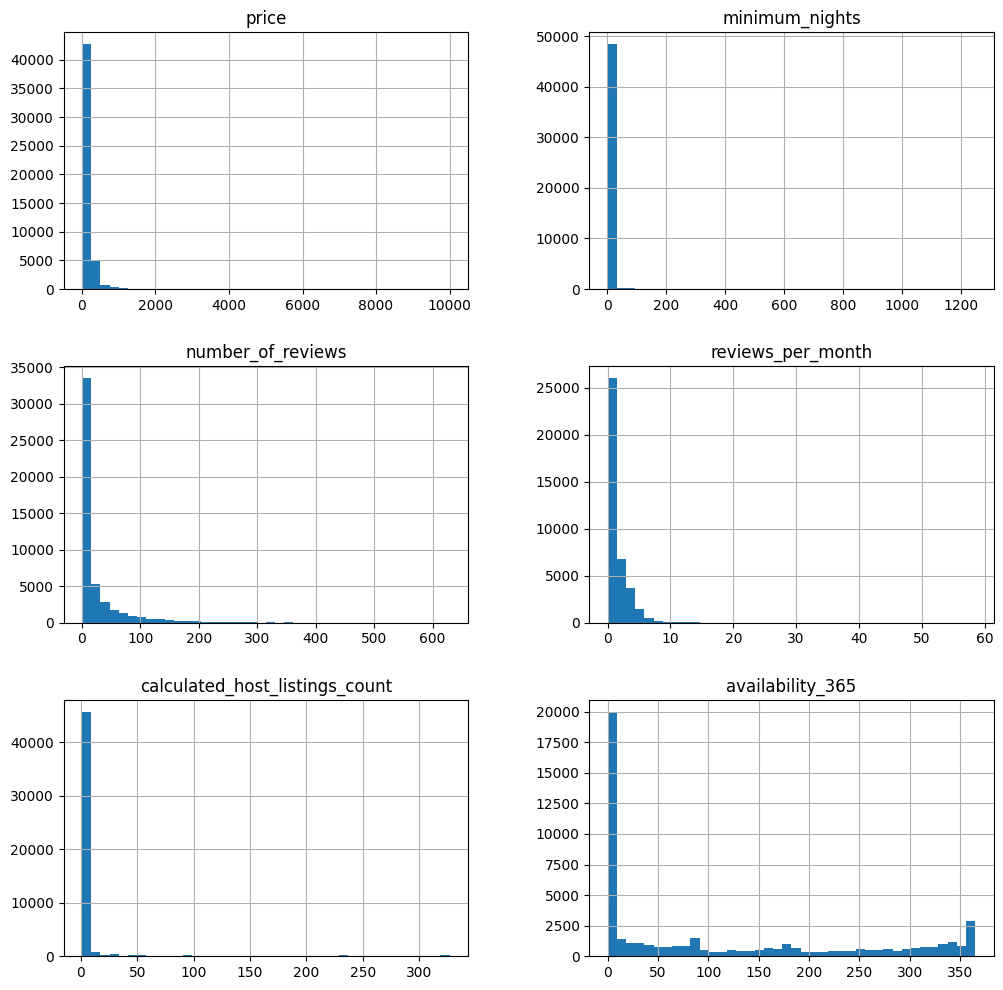

In [27]:
df[numeric_cols].hist(bins=40, figsize=(12, 12))
plt.show()

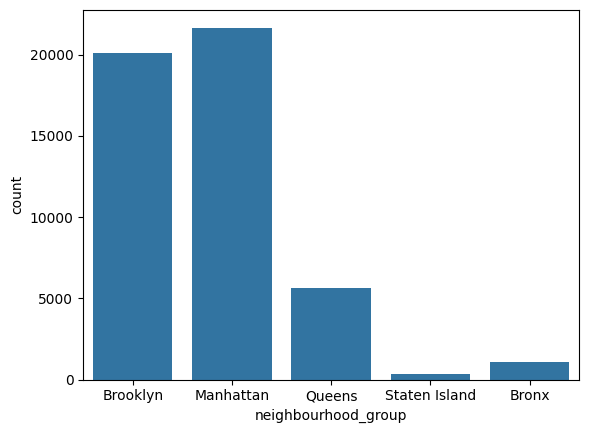

In [22]:
sns.countplot(data=df, x='neighbourhood_group')
plt.show()

Features vs target (bivariate analysis)

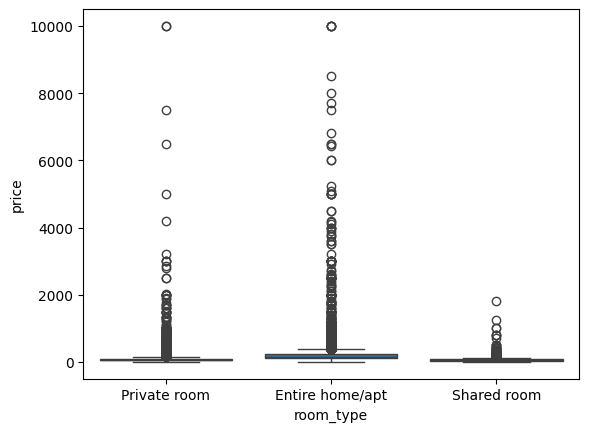

In [23]:
sns.boxplot(x='room_type',y='price',data=df)
plt.show()

In [28]:
corr=df[numeric_cols+['latitude','longitude']].corr()

In [29]:
corr

,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,latitude,longitude
price,1.000000,0.042799,-0.047954,-0.030608,0.057472,0.081829,0.033939,-0.150019
minimum_nights,0.042799,1.000000,-0.080116,-0.121702,0.127960,0.144303,0.024869,-0.062747
number_of_reviews,-0.047954,-0.080116,1.000000,0.549868,-0.072376,0.172028,-0.015389,0.059094
reviews_per_month,-0.030608,-0.121702,0.549868,1.000000,-0.009421,0.185791,-0.010142,0.145948
calculated_host_listings_count,0.057472,0.127960,-0.072376,-0.009421,1.000000,0.225701,0.019517,-0.114713
availability_365,0.081829,0.144303,0.172028,0.185791,0.225701,1.000000,-0.010983,0.082731
latitude,0.033939,0.024869,-0.015389,-0.010142,0.019517,-0.010983,1.000000,0.084788
longitude,-0.150019,-0.062747,0.059094,0.145948,-0.114713,0.082731,0.084788,1.000000


<Axes: >

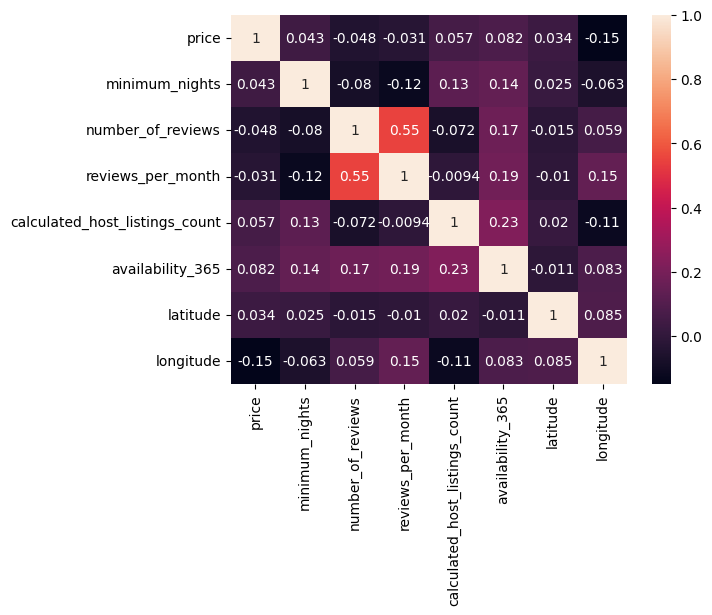

In [30]:
sns.heatmap(corr,annot=True)

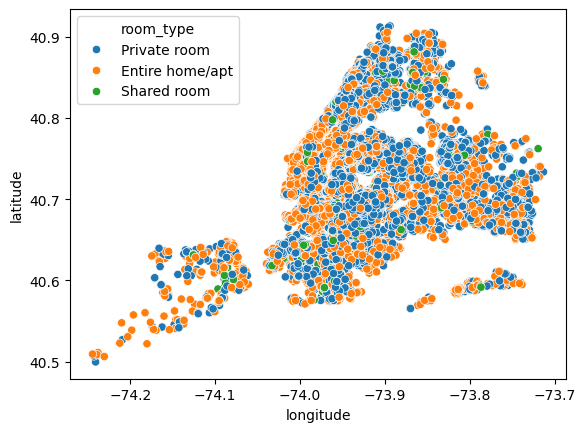

In [35]:

sns.scatterplot(x='longitude',y='latitude',data=df,hue='room_type')
plt.show()

# Stage 2A — Leakage-Safe Data Splitting and Feature Preparation

This stage creates two independent evaluation benchmarks and two prediction-time feature scenarios. It performs no imputation, scaling, outlier removal, or model fitting.

- **Protocol 1:** stratified listing-level random split (host overlap is measured and reported).
- **Protocol 2:** host-grouped split for evaluation on unseen hosts (zero host overlap is enforced).
- **Scenario A:** cold-start feature subset.
- **Scenario B:** existing-listing feature subset, retaining review-history missing values for later pipeline imputation.

In [ ]:
# Stage 2A: leakage-safe splitting and four feature matrices
from sklearn.model_selection import train_test_split, GroupShuffleSplit

# -----------------------------------------------------------------------------
# 1. Separate target, grouping variable, and predictive features
# -----------------------------------------------------------------------------
y_raw = df['room_type'].copy()
groups_raw = df['host_id'].copy()

metadata_and_targets = [
    'room_type', 'host_id', 'id', 'name', 'host_name', 'last_review'
]
X_raw = df.drop(columns=metadata_and_targets).copy()

cold_start_cols = [
    'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude',
    'price', 'minimum_nights', 'availability_365',
    'calculated_host_listings_count'
]
existing_listing_cols = cold_start_cols + [
    'number_of_reviews', 'reviews_per_month'
]

# Fail early if the dataset schema differs from the design.
missing_feature_cols = sorted(
    set(existing_listing_cols).difference(X_raw.columns)
)
if missing_feature_cols:
    raise KeyError(f'Missing required predictor columns: {missing_feature_cols}')

# -----------------------------------------------------------------------------
# 2. Pre-split integrity checks
# -----------------------------------------------------------------------------
assert df.index.is_unique, 'Input dataframe index must be unique.'
assert X_raw.index.equals(y_raw.index), 'X_raw and y_raw indices are misaligned.'
assert X_raw.index.equals(groups_raw.index), 'X_raw and groups_raw indices are misaligned.'
assert y_raw.notna().all(), 'Target contains missing values.'
assert groups_raw.notna().all(), 'Host grouping variable contains missing values.'
assert 'room_type' not in X_raw.columns, 'Target leakage: room_type is in X_raw.'
assert 'host_id' not in X_raw.columns, 'Group identifier leakage: host_id is in X_raw.'
assert not set(metadata_and_targets).intersection(X_raw.columns), (
    'One or more target/metadata columns remain in X_raw.'
)

class_labels = sorted(y_raw.unique().tolist())
print('=' * 76)
print('STAGE 2A — INPUT INTEGRITY')
print('=' * 76)
print(f'Original rows: {len(df):,}')
print(f'Predictive columns in X_raw: {X_raw.columns.tolist()}')
print(f'Target classes: {class_labels}')
print(f'Missing reviews_per_month values retained (not imputed): '
      f'{X_raw["reviews_per_month"].isna().sum():,}')
print('Pre-split alignment and leakage-boundary assertions: PASSED')

# -----------------------------------------------------------------------------
# 3. Protocol 1 — stratified listing-level random benchmark
# -----------------------------------------------------------------------------
X_train_rand_raw, X_test_rand_raw, y_train_rand, y_test_rand = train_test_split(
    X_raw,
    y_raw,
    test_size=0.30,
    random_state=42,
    stratify=y_raw
)

rand_train_idx = set(X_train_rand_raw.index)
rand_test_idx = set(X_test_rand_raw.index)
assert rand_train_idx.isdisjoint(rand_test_idx), (
    'Protocol 1: train and test indices overlap.'
)
assert rand_train_idx.union(rand_test_idx) == set(X_raw.index), (
    'Protocol 1: train/test partitions do not cover the complete dataset.'
)
assert len(X_train_rand_raw) + len(X_test_rand_raw) == len(df)

# Host overlap is expected in this listing-level benchmark; report, do not hide it.
overlapping_hosts_rand = (
    set(groups_raw.loc[X_train_rand_raw.index])
    .intersection(set(groups_raw.loc[X_test_rand_raw.index]))
)

print('\n' + '=' * 76)
print('PROTOCOL 1 — STRATIFIED RANDOM LISTING-LEVEL BENCHMARK')
print('=' * 76)
print(f'Train rows: {len(X_train_rand_raw):,} '
      f'({len(X_train_rand_raw) / len(df) * 100:.2f}%)')
print(f'Test rows : {len(X_test_rand_raw):,} '
      f'({len(X_test_rand_raw) / len(df) * 100:.2f}%)')
print(f'Host overlap (expected for this protocol): {len(overlapping_hosts_rand):,}')
print('Train/test disjointness and complete-coverage assertions: PASSED')

# -----------------------------------------------------------------------------
# 4. Protocol 2 — host-grouped unseen-host benchmark
# -----------------------------------------------------------------------------
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_pos, test_pos = next(gss.split(X_raw, y_raw, groups=groups_raw))

# GroupShuffleSplit returns positional indices; iloc preserves the intended rows.
X_train_grp_raw = X_raw.iloc[train_pos].copy()
X_test_grp_raw = X_raw.iloc[test_pos].copy()
y_train_grp = y_raw.iloc[train_pos].copy()
y_test_grp = y_raw.iloc[test_pos].copy()

grp_train_idx = set(X_train_grp_raw.index)
grp_test_idx = set(X_test_grp_raw.index)
assert grp_train_idx.isdisjoint(grp_test_idx), (
    'Protocol 2: train and test indices overlap.'
)
assert grp_train_idx.union(grp_test_idx) == set(X_raw.index), (
    'Protocol 2: train/test partitions do not cover the complete dataset.'
)
assert len(X_train_grp_raw) + len(X_test_grp_raw) == len(df)

overlapping_hosts_grp = (
    set(groups_raw.loc[X_train_grp_raw.index])
    .intersection(set(groups_raw.loc[X_test_grp_raw.index]))
)
assert len(overlapping_hosts_grp) == 0, (
    'CRITICAL: host-level leakage detected in grouped benchmark.'
)

print('\n' + '=' * 76)
print('PROTOCOL 2 — HOST-GROUPED UNSEEN-HOST BENCHMARK')
print('=' * 76)
print(f'Train rows: {len(X_train_grp_raw):,} '
      f'({len(X_train_grp_raw) / len(df) * 100:.2f}%)')
print(f'Test rows : {len(X_test_grp_raw):,} '
      f'({len(X_test_grp_raw) / len(df) * 100:.2f}%)')
print(f'Unique train hosts: {groups_raw.loc[X_train_grp_raw.index].nunique():,}')
print(f'Unique test hosts : {groups_raw.loc[X_test_grp_raw.index].nunique():,}')
print(f'Host overlap: {len(overlapping_hosts_grp)}')
print('Train/test disjointness, complete coverage, and zero-host-overlap assertions: PASSED')

# Show every target class, including a zero count if a class is absent.
train_counts = y_train_grp.value_counts().reindex(class_labels, fill_value=0)
test_counts = y_test_grp.value_counts().reindex(class_labels, fill_value=0)
train_pcts = y_train_grp.value_counts(normalize=True).reindex(class_labels, fill_value=0) * 100
test_pcts = y_test_grp.value_counts(normalize=True).reindex(class_labels, fill_value=0) * 100

print('\nGrouped training class distribution:')
for label in class_labels:
    print(f'  {label}: {train_counts[label]:,} ({train_pcts[label]:.2f}%)')

print('\nGrouped test class distribution:')
for label in class_labels:
    print(f'  {label}: {test_counts[label]:,} ({test_pcts[label]:.2f}%)')

missing_train_classes = [label for label in class_labels if train_counts[label] == 0]
missing_test_classes = [label for label in class_labels if test_counts[label] == 0]
if missing_train_classes or missing_test_classes:
    raise ValueError(
        'Grouped split is missing target classes. '
        f'Train missing: {missing_train_classes}; test missing: {missing_test_classes}. '
        'Stop before model evaluation and review a group-aware stratification strategy.'
    )

# Minority-class diagnostics: listings and independent host groups are both reported.
shared_label = 'Shared room'
shared_test_mask = y_test_grp.eq(shared_label)
shared_test_listings_count = int(shared_test_mask.sum())
shared_test_hosts = int(
    groups_raw.loc[y_test_grp.index[shared_test_mask]].nunique()
)
shared_test_pct = float(test_pcts.get(shared_label, 0.0))

print('\nShared room grouped-test diagnostics:')
print(f'  Listings: {shared_test_listings_count:,} ({shared_test_pct:.2f}% of grouped test set)')
print(f'  Unique contributing hosts: {shared_test_hosts:,}')

# This is a provisional operational floor, NOT a statistical representativeness guarantee.
MIN_SHARED_ROOM_TEST_LISTINGS = 100
if shared_test_listings_count < MIN_SHARED_ROOM_TEST_LISTINGS:
    raise ValueError(
        'Provisional operational safeguard failed: '
        f'{shared_test_listings_count} Shared room test listings is below '
        f'{MIN_SHARED_ROOM_TEST_LISTINGS}. Do not tune the seed silently; '
        'review a defensible group-aware split strategy.'
    )
print(
    'Provisional Shared room listing-count safeguard: PASSED '
    '(this does not establish statistical representativeness).'
)

# -----------------------------------------------------------------------------
# 5. Create the four raw feature matrices (no preprocessing or imputation)
# -----------------------------------------------------------------------------
# Protocol 1: random benchmark
X_train_rand_cold = X_train_rand_raw[cold_start_cols].copy()
X_test_rand_cold = X_test_rand_raw[cold_start_cols].copy()
X_train_rand_warm = X_train_rand_raw[existing_listing_cols].copy()
X_test_rand_warm = X_test_rand_raw[existing_listing_cols].copy()

# Protocol 2: unseen-host grouped benchmark
X_train_grp_cold = X_train_grp_raw[cold_start_cols].copy()
X_test_grp_cold = X_test_grp_raw[cold_start_cols].copy()
X_train_grp_warm = X_train_grp_raw[existing_listing_cols].copy()
X_test_grp_warm = X_test_grp_raw[existing_listing_cols].copy()

# Final feature/index integrity checks for all four configurations.
feature_sets = {
    'random cold train': (X_train_rand_cold, cold_start_cols, y_train_rand),
    'random cold test': (X_test_rand_cold, cold_start_cols, y_test_rand),
    'random existing train': (X_train_rand_warm, existing_listing_cols, y_train_rand),
    'random existing test': (X_test_rand_warm, existing_listing_cols, y_test_rand),
    'grouped cold train': (X_train_grp_cold, cold_start_cols, y_train_grp),
    'grouped cold test': (X_test_grp_cold, cold_start_cols, y_test_grp),
    'grouped existing train': (X_train_grp_warm, existing_listing_cols, y_train_grp),
    'grouped existing test': (X_test_grp_warm, existing_listing_cols, y_test_grp),
}
for matrix_name, (matrix, expected_cols, aligned_target) in feature_sets.items():
    assert matrix.columns.tolist() == expected_cols, (
        f'{matrix_name}: unexpected feature columns.'
    )
    assert matrix.index.equals(aligned_target.index), (
        f'{matrix_name}: feature and target indices are misaligned.'
    )
    assert 'room_type' not in matrix.columns and 'host_id' not in matrix.columns

print('\n' + '=' * 76)
print('STAGE 2A COMPLETE — FOUR RAW FEATURE CONFIGURATIONS CREATED')
print('=' * 76)
print('1. Random benchmark + cold-start')
print('2. Random benchmark + existing-listing')
print('3. Host-grouped benchmark + cold-start')
print('4. Host-grouped benchmark + existing-listing')
print('No imputation, scaling, encoding, outlier filtering, or model fitting was performed.')
print('All final feature matrices are index-aligned with their corresponding targets.')


### Stage 2A — Interpretation and limitations

- The random benchmark is listing-level and permits host overlap; it is a conventional baseline, not an unseen-host estimate.
- The grouped benchmark enforces zero host overlap, but `GroupShuffleSplit` does not stratify the target. Class distributions must be reviewed as printed above.
- The 100-listing Shared room floor is a provisional operational safeguard, not a statistical guarantee. The number of distinct contributing hosts is reported separately.
- `availability_365` and `calculated_host_listings_count` are assumed available for the intended prediction workflow; this 2019 snapshot does not prove their availability at original listing creation.
- The dataset is cross-sectional. Neither split simulates genuine out-of-time deployment or post-2019 regulatory and market changes.
- Existing-listing `reviews_per_month` missing values remain untouched here. In the later modeling stage, use `SimpleImputer(strategy="constant", fill_value=0)` inside the scenario-specific scikit-learn pipeline so it is fitted within each training fold.
- Multiple listings from one host may be correlated. Grouped evaluation prevents cross-partition host overlap but does not make listings within a partition statistically independent.

## Stage 2B — Scenario-Specific Preprocessing and Model Validation (NEXT STAGE)

**Do not run the legacy preprocessing/model cells below yet.** They still reference the previous `X_train` / `X_test` workflow and must be refactored to use the four Stage 2A configurations. Stage 2B will implement fold-local preprocessing, cross-validation, and model evaluation.

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler,PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [ ]:
from sklearn.preprocessing import QuantileTransformer

numeric_cols = ['price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'latitude', 'longitude']
categorical_cols = ['neighbourhood_group', 'neighbourhood']

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('skewness', QuantileTransformer(output_distribution='normal', random_state=42)),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, numeric_cols),
    ('cat', categorical_pipeline, categorical_cols)
])

In [ ]:
preprocessor

In [ ]:
df_clean[numeric_cols].skew()

In [ ]:
# trying multiple ml algortihms

#Smote-for hadling data imbalance

but not used as high chances of
1.overfitting
2.fills fake values

# class weight-it is used for focusing on the values that appeared least times ,focus equally on every appeared

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline

# Ensure train/test split is defined and aligned
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

models = {
    'LogisticRegression': LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000),
    'DecisionTree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'RandomForest': RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    'GradientBoosting': GradientBoostingClassifier()
}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    accuracy = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='accuracy')
    macrof1 = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='f1_macro')

    print(f"=== {name} ===")
    print(f"Mean Accuracy: {accuracy.mean():.4f} (+/- {accuracy.std():.4f})")
    print(f"Mean Macro F1: {macrof1.mean():.4f} (+/- {macrof1.std():.4f})\n")

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Pipeline with our preprocessor and RandomForest classifier
tuning_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1))
])

# Define the hyperparameter search space
param_dist = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [10, 20, 30, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

# Set up randomized search cross-validation
rf_random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_dist,
    n_iter=5,
    cv=3,
    scoring='f1_macro',
    random_state=42,
    n_jobs=-1
)

# Run the hyperparameter optimization
print("Optimizing RandomForest hyperparameters...")
rf_random_search.fit(X_train, y_train)
print("Best parameters found:", rf_random_search.best_params_)
print(f"Best Cross-Validation Macro F1 Score: {rf_random_search.best_score_:.4f}")

In [ ]:
rf_random_search.fit(X_train, y_train)

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Get the best estimator from our randomized search
best_model = rf_random_search.best_estimator_

# Make predictions on the test dataset
y_pred = best_model.predict(X_test)

# Calculate final scores
test_acc = accuracy_score(y_test, y_pred)
print(f"=== Final Evaluation on Test Set ===")
print(f"Test Accuracy: {test_acc:.4f}")

# Display the classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Plot the Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred, labels=best_model.classes_)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=best_model.classes_, yticklabels=best_model.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix on Test Dataset')
plt.show()